# Student Behaviour Clustering

K-means analysis of four behavioural variables, with a separate six-feature sensitivity analysis. Model selection uses development records; held-out records are used for evaluation. Outcome labels are excluded from clustering and model selection.

## 1. Configuration

Silhouette scores are computed on all records in the standardised feature space using chunked distance calculations.

In [1]:
from pathlib import Path
import os, json, hashlib, platform, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn import config_context
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_samples, silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATA_DIR = Path(os.environ['E_DATA_DIR']) if 'E_DATA_DIR' in os.environ else next(
    (p for p in [ROOT / 'data', ROOT, ROOT / '6312_A', ROOT.parent / '6312_A']
     if (p / 'processed_data.csv').exists()), ROOT / 'data')
OUT = Path(os.environ.get('E_OUTPUT_DIR', str(ROOT / 'results')))
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
K_VALUES = list(range(2, 7))
N_INIT = 30                     # Explicit value for reproducibility across library versions.
STABILITY_SEEDS = list(range(10))
RUN_SIX_FEATURE_SENSITIVITY = True
FEATURES = ['Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours',
            'Sleep_Hours', 'Physical_Activity_Hours']
HEALTH = ['Mental_Health_Score', 'Physical_Health_Score', 'Social_Isolation_Score']
SCALED_COLS = ['Age'] + FEATURES + HEALTH
OUTCOMES = ['Burnout_Level', 'Academic_Performance_Score', 'Academic_Failure_Risk']
SHORT = ['Social media', 'AI tools', 'Sleep', 'Physical activity']
BURNOUT = {0: 'Low', 1: 'Moderate', 2: 'High', 3: 'Severe'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#2676A5', '#E4973E', '#59A386', '#AF6D9F', '#8577B5', '#73808C']
def table(frame):
    try:
        from IPython.display import display
        display(frame)
    except ImportError:
        print(frame.to_string())

def savefig(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


## 2. Data validation

Row alignment is checked against the encoded source data before restoring student identifiers. The supplied split and training-based scaling are reproduced for verification. Clustering uses the supplied standardised values.

In [2]:
raw_path = DATA_DIR / 'AI_SocialMedia_Student_Health_Dataset_clean.csv'
raw = pd.read_csv(raw_path)
data = pd.read_csv(DATA_DIR / 'processed_data.csv')
scaled = pd.read_csv(DATA_DIR / 'processed_data_scaled.csv')
assert len(raw) == len(data) == len(scaled), 'Row counts differ across the three CSV files.'
assert list(data.columns) == list(scaled.columns), 'Processed files have different column orders.'
assert raw['Student_ID'].is_unique, 'Source student identifiers are not unique.'
assert not raw.isna().any().any() and not data.isna().any().any() and not scaled.isna().any().any()
assert set(data['split']) == {'train', 'test'}
assert data['split'].equals(scaled['split'])
expected = raw.drop(columns='Student_ID').copy()
expected['Burnout_Level'] = expected['Burnout_Level'].map({v: k for k, v in BURNOUT.items()})
expected = pd.get_dummies(expected, columns=['Gender', 'Education_Level'], drop_first=True, dtype=int)
assert set(expected.columns) == set(data.columns) - {'split'}
pd.testing.assert_frame_equal(expected[data.drop(columns='split').columns], data.drop(columns='split'),
                              check_dtype=False, check_exact=False, atol=1e-10, rtol=1e-10)
train_mask = data['split'].eq('train').to_numpy()
test_mask = ~train_mask
strata = data['Burnout_Level'].astype(str) + '_' + data['Academic_Failure_Risk'].astype(str)
_, test_idx = train_test_split(data.index, test_size=0.2, random_state=SEED, stratify=strata)
assert set(np.flatnonzero(test_mask)) == set(test_idx), 'Split does not match the preprocessing notebook.'
audit_scaler = StandardScaler().fit(data.loc[train_mask, SCALED_COLS])
reconstructed = audit_scaler.transform(data[SCALED_COLS])
assert np.isfinite(scaled[SCALED_COLS].to_numpy()).all()
np.testing.assert_allclose(reconstructed, scaled[SCALED_COLS], atol=1e-10, rtol=1e-10)
pd.testing.assert_frame_equal(data.drop(columns=SCALED_COLS), scaled.drop(columns=SCALED_COLS))
assert not set(FEATURES) & set(OUTCOMES + HEALTH + ['Student_ID', 'split'])
print(f'Data validation passed: {len(data):,} records; development: {train_mask.sum():,}; held out: {test_mask.sum():,}.')
pd.DataFrame({'feature': SCALED_COLS, 'train_mean': audit_scaler.mean_,
              'train_scale_ddof0': audit_scaler.scale_}).to_csv(OUT / 'scaler_parameters.csv', index=False)
audit = {'rows': len(data), 'train_rows': int(train_mask.sum()), 'test_rows': int(test_mask.sum()),
         'raw_columns': len(raw.columns), 'processed_columns': len(data.columns),
         'raw_duplicate_rows': int(raw.duplicated().sum()),
         'max_scaling_absolute_error': float(np.max(np.abs(reconstructed - scaled[SCALED_COLS].to_numpy()))),
         'row_alignment_verified': True, 'split_reproduced': True,
         'sha256': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in DATA_DIR.glob('*.csv')}}
(OUT / 'data_audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')

Data validation passed: 15,000 records; development: 12,000; held out: 3,000.


591

## 3. Candidate models

Candidate values of k range from 2 to 6. Initialisation stability is measured using all 45 pairwise adjusted Rand indices across 10 seeds, separately for one and 30 initialisations. These comparisons measure initialisation sensitivity, not sampling stability.

In [3]:
def evaluate_candidates(X, prefix):
    rows, stability_rows, size_rows, models = [], [], [], {}
    with threadpool_limits(limits=1), config_context(working_memory=128):
        for k in K_VALUES:
            model = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED,
                           max_iter=500, algorithm='lloyd').fit(X)
            models[k] = model
            counts = np.bincount(model.labels_, minlength=k)
            rec = {'k': k, 'silhouette': silhouette_score(X, model.labels_),
                   'inertia': model.inertia_, 'min_cluster_n': counts.min(),
                   'max_cluster_n': counts.max(), 'min_cluster_fraction': counts.min()/len(X),
                   'n_iter': model.n_iter_}
            for c, n in enumerate(counts):
                size_rows.append({'k': k, 'raw_cluster': c, 'n': n, 'fraction': n/len(X)})
            for starts, label in [(1, 'single'), (N_INIT, 'multi')]:
                runs = [KMeans(n_clusters=k, n_init=starts, random_state=s,
                               max_iter=500, algorithm='lloyd').fit_predict(X)
                        for s in STABILITY_SEEDS]
                aris = []
                for i, j in itertools.combinations(range(len(runs)), 2):
                    ari = adjusted_rand_score(runs[i], runs[j]); aris.append(ari)
                    stability_rows.append({'k': k, 'n_init': starts, 'seed_a': STABILITY_SEEDS[i],
                                           'seed_b': STABILITY_SEEDS[j], 'ARI': ari})
                rec.update({f'ari_{label}_mean': np.mean(aris), f'ari_{label}_min': np.min(aris),
                            f'ari_{label}_std': np.std(aris, ddof=1)})
            rows.append(rec)
            print(f'{prefix}: k={k}, silhouette={rec["silhouette"]:.4f}, '
                  f'ARI(30 starts)={rec["ari_multi_mean"]:.4f}', flush=True)
    metrics = pd.DataFrame(rows)
    metrics['inertia_drop_fraction'] = -metrics['inertia'].pct_change()
    metrics.to_csv(OUT / f'{prefix}_k_comparison.csv', index=False)
    pd.DataFrame(stability_rows).to_csv(OUT / f'{prefix}_stability_pairs.csv', index=False)
    pd.DataFrame(size_rows).to_csv(OUT / f'{prefix}_candidate_sizes.csv', index=False)
    return metrics, models

X_train = scaled.loc[train_mask, FEATURES].to_numpy()
X_test = scaled.loc[test_mask, FEATURES].to_numpy()
metrics, models = evaluate_candidates(X_train, 'main4')
table(metrics.round(4))

main4: k=2, silhouette=0.2024, ARI(30 starts)=0.9927


main4: k=3, silhouette=0.1941, ARI(30 starts)=0.9879


main4: k=4, silhouette=0.1914, ARI(30 starts)=0.9710


main4: k=5, silhouette=0.1786, ARI(30 starts)=0.9802


main4: k=6, silhouette=0.1738, ARI(30 starts)=0.8683


,k,silhouette,inertia,min_cluster_n,max_cluster_n,min_cluster_fraction,n_iter,ari_single_mean,ari_single_min,ari_single_std,ari_multi_mean,ari_multi_min,ari_multi_std,inertia_drop_fraction
0,2,0.2024,37409.6569,5917,6083,0.4931,15,0.9821,0.9673,0.0098,0.9927,0.9867,0.0035,NaN
1,3,0.1941,31505.7982,3422,4350,0.2852,25,0.6160,0.2079,0.3842,0.9879,0.9757,0.0063,0.1578
2,4,0.1914,27339.2465,2659,3305,0.2216,27,0.8777,0.7547,0.0885,0.9710,0.9464,0.0124,0.1322
3,5,0.1786,24960.1964,2161,2830,0.1801,61,0.7328,0.4361,0.1838,0.9802,0.9457,0.0146,0.0870
4,6,0.1738,23130.9970,1802,2235,0.1502,48,0.3880,0.2434,0.1290,0.8683,0.4987,0.1835,0.0733


## 4. Model selection and held-out evaluation

The selected model maximises development-set silhouette, with smaller k used to break exact ties. Cluster sizes, inertia and initialisation stability are reported alongside silhouette. The fitted centroids remain fixed during held-out evaluation.

Selected k=2; centroids fixed for profiling and held-out evaluation.


,partition,n,k_observed,silhouette,negative_silhouette_fraction,mean_squared_distance_to_train_centroid
0,development,12000,2,0.2024,0.0177,3.1175
1,held_out,3000,2,0.2030,0.0190,3.1241


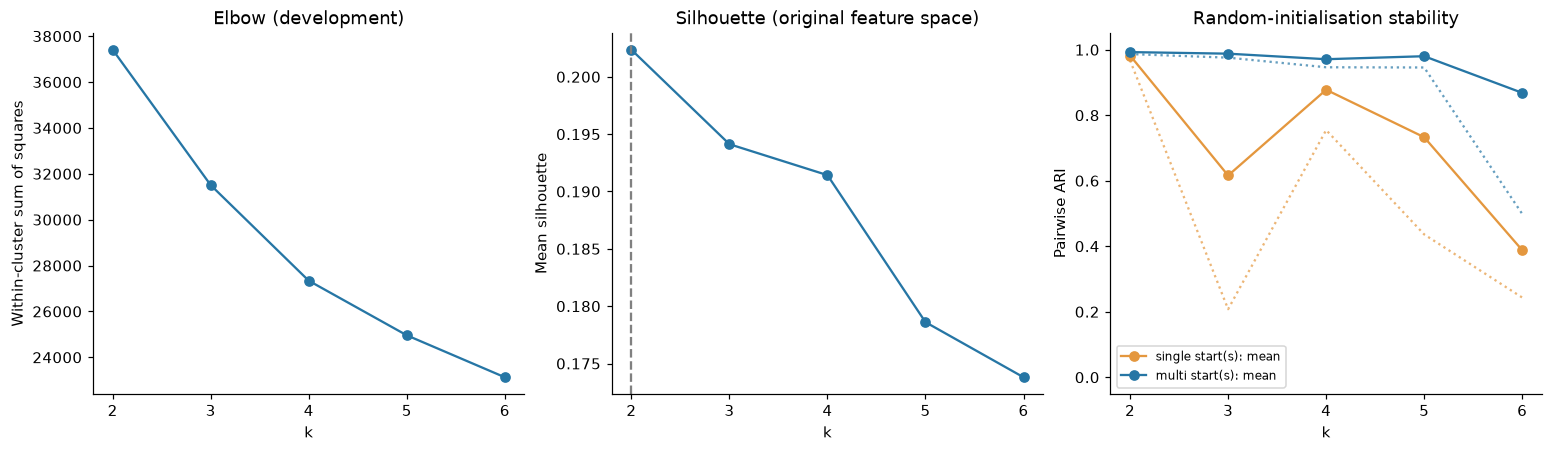

In [4]:
chosen_k = int(metrics.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
model = models[chosen_k]
# Order display labels by social-media centroid; labels do not indicate risk levels.
order = np.argsort(model.cluster_centers_[:, 0])
label_map = {int(old): int(new+1) for new, old in enumerate(order)}
def relabel(labels):
    return np.array([label_map[int(x)] for x in labels])
labels_train = relabel(model.labels_)
labels_test = relabel(model.predict(X_test))
labels_all = relabel(model.predict(scaled[FEATURES].to_numpy()))
with threadpool_limits(limits=1), config_context(working_memory=128):
    sil_train = silhouette_samples(X_train, labels_train)
    sil_test = silhouette_samples(X_test, labels_test) if len(np.unique(labels_test)) > 1 else np.full(len(X_test), np.nan)
evaluation = pd.DataFrame([
    {'partition': 'development', 'n': len(X_train), 'k_observed': len(np.unique(labels_train)),
     'silhouette': np.mean(sil_train), 'negative_silhouette_fraction': np.mean(sil_train < 0),
     'mean_squared_distance_to_train_centroid': model.inertia_/len(X_train)},
    {'partition': 'held_out', 'n': len(X_test), 'k_observed': len(np.unique(labels_test)),
     'silhouette': np.mean(sil_test), 'negative_silhouette_fraction': np.mean(sil_test < 0),
     'mean_squared_distance_to_train_centroid': np.min(model.transform(X_test), axis=1).dot(
         np.min(model.transform(X_test), axis=1))/len(X_test)}])
evaluation.to_csv(OUT / 'main4_final_evaluation.csv', index=False)
print(f'Selected k={chosen_k}; centroids fixed for profiling and held-out evaluation.')
table(evaluation.round(4))
fig, ax = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
ax[0].plot(metrics.k, metrics.inertia, 'o-', color=COLORS[0]); ax[0].set(title='Elbow (development)', ylabel='Within-cluster sum of squares')
ax[1].plot(metrics.k, metrics.silhouette, 'o-', color=COLORS[0]); ax[1].axvline(chosen_k, color='gray', ls='--'); ax[1].set(title='Silhouette (original feature space)', ylabel='Mean silhouette')
for label, color in [('single', COLORS[1]), ('multi', COLORS[0])]:
    ax[2].plot(metrics.k, metrics[f'ari_{label}_mean'], 'o-', color=color, label=f'{label} start(s): mean')
    ax[2].plot(metrics.k, metrics[f'ari_{label}_min'], ':', color=color, alpha=.7)
ax[2].set(title='Random-initialisation stability', ylabel='Pairwise ARI', ylim=(-.05,1.05)); ax[2].legend(fontsize=8)
for a in ax: a.set_xlabel('k'); a.set_xticks(K_VALUES)
savefig(fig, '01_k_selection')

## 5. Cluster profiles and outcomes

Behavioural profiles are reported in original units for each partition. Outcome and health variables are summarised after model selection. These comparisons describe associations within the dataset.

Daily_Social_Media_Hours  Daily_AI_Tool_Usage_Hours  \
split cluster                                                        
test  1                           3.046                      2.254   
      2                           6.051                      2.835   
train 1                           3.022                      2.309   
      2                           6.097                      2.889   

               Sleep_Hours  Physical_Activity_Hours  
split cluster                                        
test  1              7.265                    1.611  
      2              5.787                    0.893  
train 1              7.263                    1.594  
      2              5.811                    0.885

,split,cluster,n,academic_mean,academic_sd,academic_median,failure_risk_fraction,burnout_Low_fraction,burnout_Moderate_fraction,burnout_High_fraction,burnout_Severe_fraction
0,test,1,1514,82.338,10.347,82.50,0.003,0.851,0.139,0.009,0.001
1,test,2,1486,74.474,11.071,74.75,0.118,0.344,0.423,0.173,0.060
2,train,1,6083,82.364,10.385,82.69,0.002,0.853,0.137,0.009,0.001
3,train,2,5917,74.087,11.239,74.09,0.120,0.340,0.427,0.173,0.060


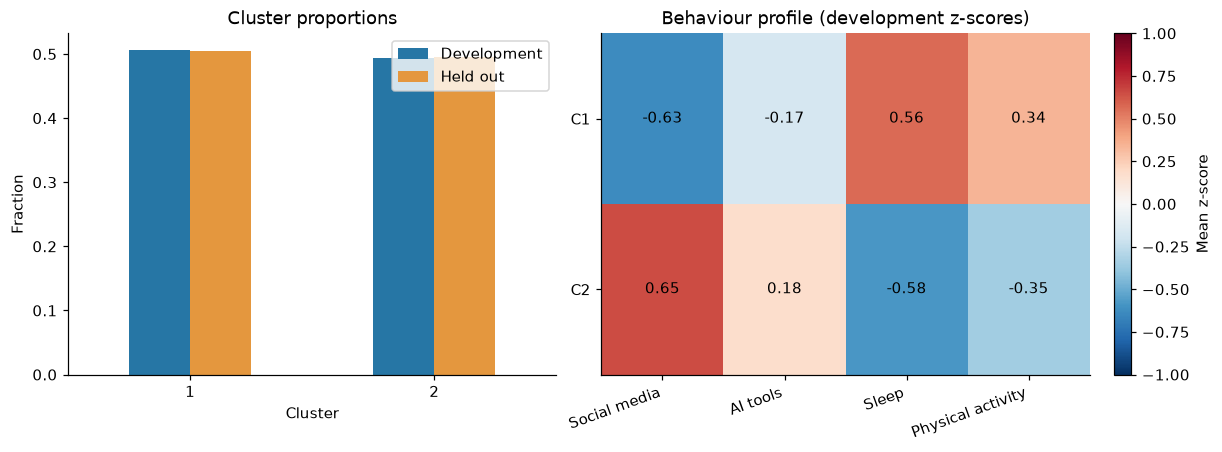

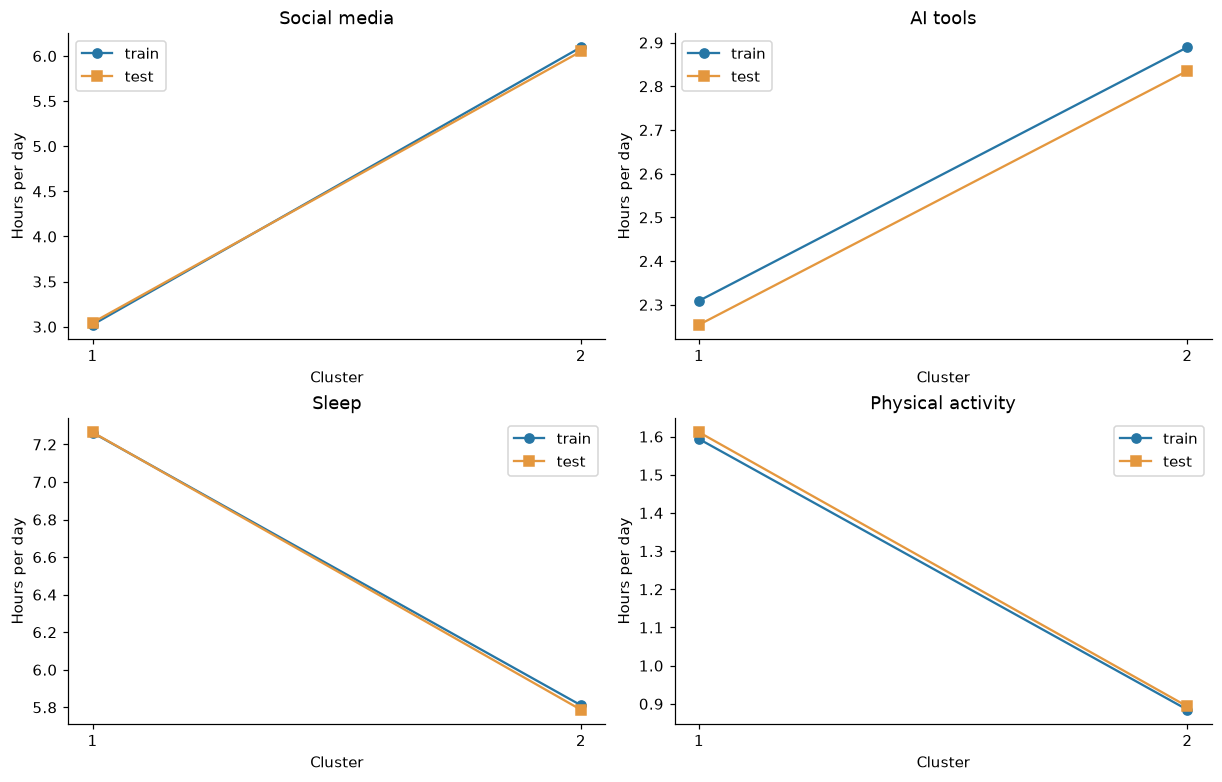

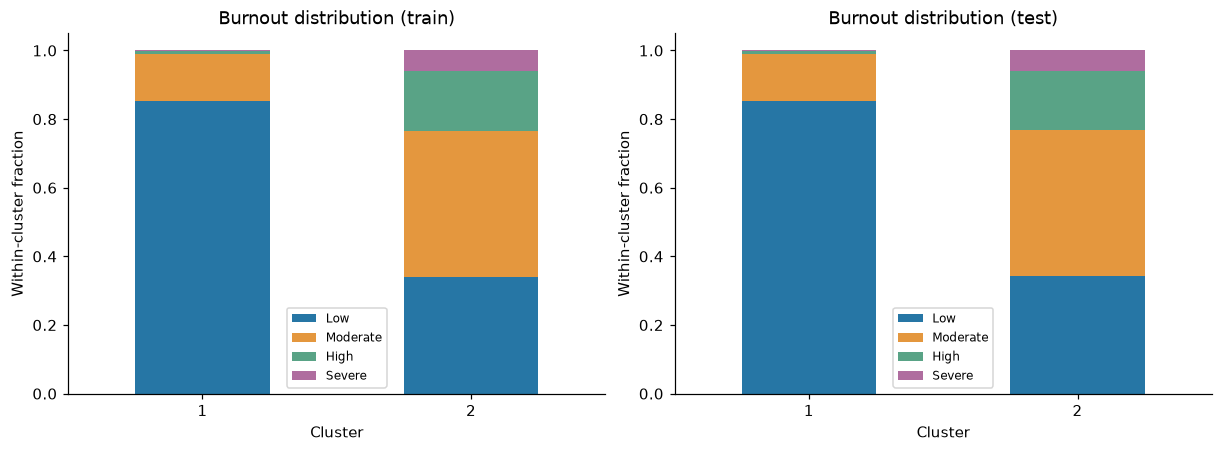

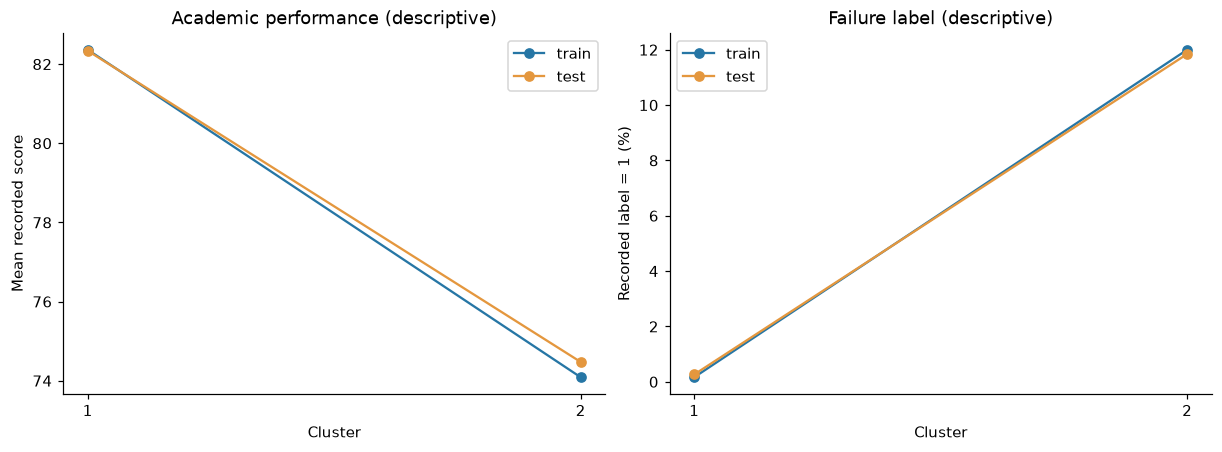

In [5]:
assigned = data.copy()
assigned.insert(0, 'Student_ID', raw['Student_ID'])
assigned['cluster'] = labels_all
assigned['cluster_name'] = ['C'+str(c) for c in labels_all]
assigned['Burnout_Label'] = assigned['Burnout_Level'].map(BURNOUT)
assigned.to_csv(OUT / 'main4_assignments.csv', index=False)
profile = assigned.groupby(['split', 'cluster'])[FEATURES + HEALTH + ['Academic_Performance_Score']].agg(['mean', 'median', 'std'])
profile.to_csv(OUT / 'main4_profiles_raw_units.csv')
means = assigned.groupby(['split', 'cluster'])[FEATURES].mean()
means.to_csv(OUT / 'main4_behavior_means_hours.csv')
sizes = pd.crosstab(assigned['split'], assigned['cluster']).reindex(['train', 'test'])
fractions = sizes.div(sizes.sum(axis=1), axis=0)
sizes.to_csv(OUT / 'main4_sizes.csv'); fractions.to_csv(OUT / 'main4_size_fractions.csv')
outcome_rows = []
for (split, c), g in assigned.groupby(['split', 'cluster']):
    row = {'split': split, 'cluster': c, 'n': len(g),
           'academic_mean': g['Academic_Performance_Score'].mean(),
           'academic_sd': g['Academic_Performance_Score'].std(),
           'academic_median': g['Academic_Performance_Score'].median(),
           'failure_risk_fraction': g['Academic_Failure_Risk'].mean()}
    row.update({f'burnout_{name}_fraction': g['Burnout_Label'].eq(name).mean() for name in BURNOUT.values()})
    outcome_rows.append(row)
outcome_table = pd.DataFrame(outcome_rows)
outcome_table.to_csv(OUT / 'main4_outcomes_descriptive.csv', index=False)
table(means.round(3)); table(outcome_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
fractions.T.plot.bar(ax=axes[0], color=[COLORS[0], COLORS[1]], rot=0)
axes[0].set(title='Cluster proportions', xlabel='Cluster', ylabel='Fraction'); axes[0].legend(['Development', 'Held out'])
z_means = pd.DataFrame(X_train, columns=FEATURES).assign(cluster=labels_train).groupby('cluster').mean()
im = axes[1].imshow(z_means, cmap='RdBu_r', vmin=-max(1, np.abs(z_means.to_numpy()).max()), vmax=max(1,np.abs(z_means.to_numpy()).max()), aspect='auto')
axes[1].set_xticks(range(4), SHORT, rotation=20, ha='right'); axes[1].set_yticks(range(chosen_k), [f'C{i+1}' for i in range(chosen_k)])
axes[1].set_title('Behaviour profile (development z-scores)')
for i in range(chosen_k):
    for j in range(4): axes[1].text(j, i, f'{z_means.iloc[i,j]:.2f}', ha='center', va='center')
fig.colorbar(im, ax=axes[1], label='Mean z-score')
savefig(fig, '02_sizes_and_profiles')
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
for j, (f, a) in enumerate(zip(FEATURES, axes.ravel())):
    for split, marker, color in [('train','o',COLORS[0]), ('test','s',COLORS[1])]:
        s = means.loc[split, f]; a.plot(s.index, s.values, marker+'-', label=split, color=color)
    a.set(title=SHORT[j], ylabel='Hours per day', xlabel='Cluster', xticks=range(1,chosen_k+1)); a.legend()
savefig(fig, '03_behavior_hours')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for split, ax in zip(['train','test'], axes):
    tab = pd.crosstab(assigned.loc[assigned.split.eq(split),'cluster'], assigned.loc[assigned.split.eq(split),'Burnout_Label'], normalize='index').reindex(columns=list(BURNOUT.values()), fill_value=0)
    tab.plot.bar(stacked=True, ax=ax, color=COLORS[:4], rot=0)
    ax.set(title=f'Burnout distribution ({split})', ylabel='Within-cluster fraction', xlabel='Cluster')
    ax.legend(fontsize=8)
savefig(fig, '04_burnout_descriptive')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for split, color in [('train',COLORS[0]),('test',COLORS[1])]:
    t = outcome_table.query('split == @split')
    axes[0].plot(t.cluster, t.academic_mean, 'o-', color=color, label=split)
    axes[1].plot(t.cluster, 100*t.failure_risk_fraction, 'o-', color=color, label=split)
axes[0].set(title='Academic performance (descriptive)', ylabel='Mean recorded score')
axes[1].set(title='Failure label (descriptive)', ylabel='Recorded label = 1 (%)')
for a in axes: a.set_xlabel('Cluster'); a.set_xticks(range(1,chosen_k+1)); a.legend()
savefig(fig, '05_outcomes_descriptive')

## 6. PCA visualisation

PCA is fitted on the four standardised development features and applied to held-out records. Colours represent the four-dimensional K-means assignments. Each panel displays at most 3,000 sampled records; numerical evaluations use all records in the corresponding partition.

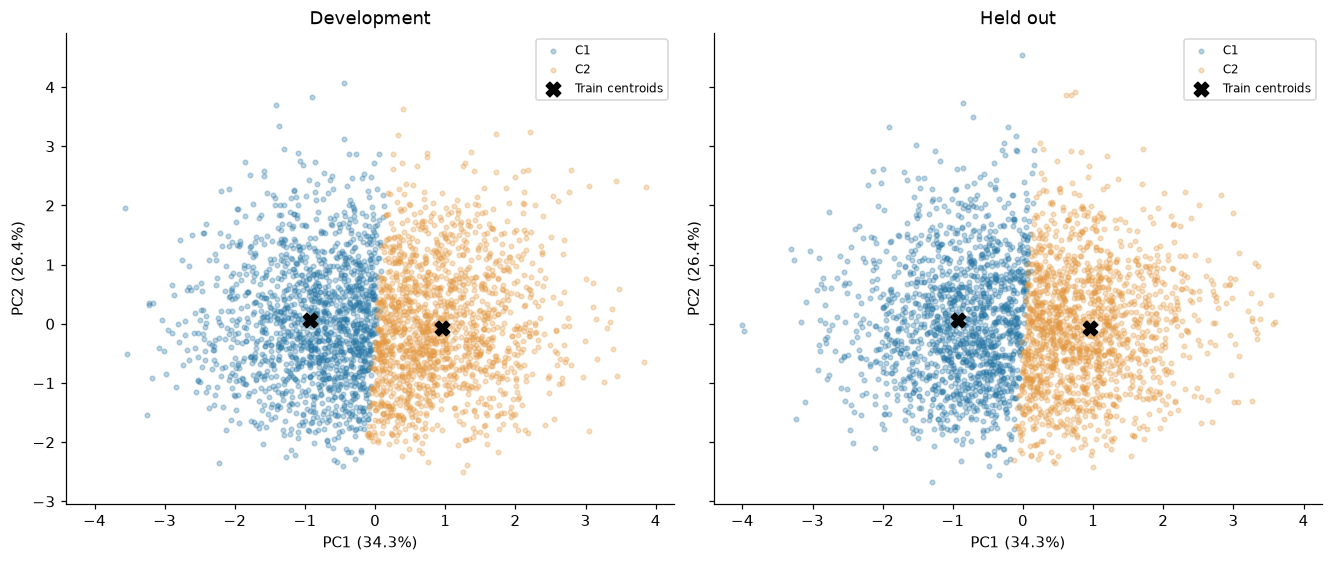

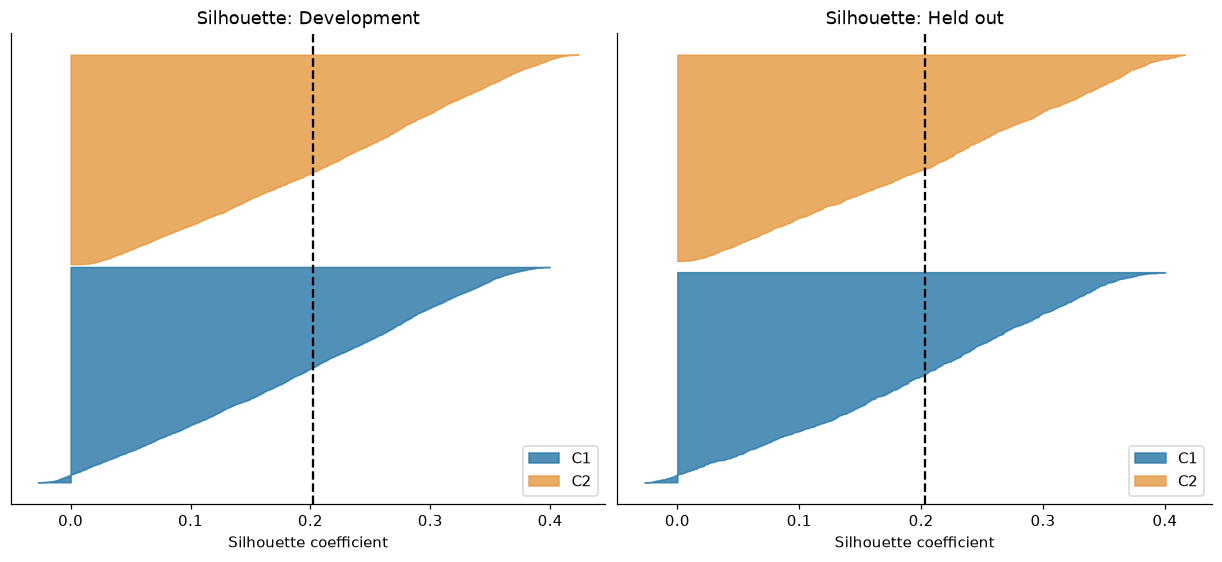

In [6]:
pca = PCA(n_components=2, svd_solver='full').fit(X_train)
proj_train, proj_test = pca.transform(X_train), pca.transform(X_test)
pd.DataFrame(pca.components_, columns=FEATURES, index=['PC1','PC2']).to_csv(OUT / 'pca_loadings.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, layout='constrained')
rng = np.random.default_rng(SEED)
centres_2d = pca.transform(model.cluster_centers_[order])
for ax, projection, labels, name in zip(axes, [proj_train, proj_test], [labels_train, labels_test], ['Development', 'Held out']):
    take = rng.choice(len(labels), min(3000, len(labels)), replace=False)
    for c in range(1, chosen_k+1):
        ids = take[labels[take] == c]
        ax.scatter(projection[ids,0], projection[ids,1], s=9, alpha=.3, color=COLORS[c-1], label=f'C{c}')
    ax.scatter(centres_2d[:,0], centres_2d[:,1], marker='X', c='black', s=90, label='Train centroids')
    ax.set(title=name, xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})'); ax.legend(fontsize=8)
savefig(fig, '06_pca_projection')
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
for ax, labels, values, name in zip(axes, [labels_train, labels_test], [sil_train, sil_test], ['Development', 'Held out']):
    bottom = 0
    for c in range(1,chosen_k+1):
        v = np.sort(values[labels == c]); y = np.arange(bottom, bottom+len(v))
        ax.fill_betweenx(y, 0, v, color=COLORS[c-1], alpha=.8, label=f'C{c}')
        bottom += len(v) + 80
    ax.axvline(np.nanmean(values), color='black', ls='--'); ax.set(title=f'Silhouette: {name}', xlabel='Silhouette coefficient', yticks=[]); ax.legend()
savefig(fig, '07_silhouette_distribution')

## 7. Six-feature sensitivity analysis

Mental health and social isolation scores are added to the four behavioural features while retaining the development/held-out protocol. Same-k ARI measures changes in cluster membership. Silhouette values from different feature spaces are not directly comparable.

In [7]:
sensitivity_summary = None
if RUN_SIX_FEATURE_SENSITIVITY:
    six_features = FEATURES + ['Mental_Health_Score', 'Social_Isolation_Score']
    X6_train, X6_test = (scaled.loc[m, six_features].to_numpy() for m in [train_mask, test_mask])
    metrics6, models6 = evaluate_candidates(X6_train, 'sensitivity6')
    k6 = int(metrics6.sort_values(['silhouette','k'], ascending=[False,True]).iloc[0]['k'])
    comparison = []
    for k in K_VALUES:
        comparison.append({'k': k, 'ARI_4vs6_development': adjusted_rand_score(models[k].labels_, models6[k].labels_)})
    pd.DataFrame(comparison).to_csv(OUT / 'sensitivity_same_k_ARI.csv', index=False)
    with threadpool_limits(limits=1), config_context(working_memory=128):
        l6test = models6[k6].predict(X6_test)
        s6test = silhouette_score(X6_test, l6test) if len(np.unique(l6test)) > 1 else float('nan')
    sensitivity_summary = {'six_feature_k': k6, 'six_feature_train_silhouette': float(metrics6.set_index('k').loc[k6,'silhouette']),
        'six_feature_test_silhouette': float(s6test),
        'same_main_k_ARI_development': float(adjusted_rand_score(model.labels_, models6[chosen_k].labels_)),
        'same_main_k_ARI_held_out': float(adjusted_rand_score(model.predict(X_test), models6[chosen_k].predict(X6_test))),
        'different_selected_k_ARI_development': float(adjusted_rand_score(model.labels_, models6[k6].labels_))}
    table(metrics6.round(4)); print(sensitivity_summary)
    pd.DataFrame({'Student_ID': raw.Student_ID, 'split': data.split,
                  'cluster6_raw': models6[k6].predict(scaled[six_features].to_numpy())}).to_csv(OUT / 'sensitivity6_assignments.csv', index=False)

sensitivity6: k=2, silhouette=0.2061, ARI(30 starts)=0.9971


sensitivity6: k=3, silhouette=0.1565, ARI(30 starts)=0.9922


sensitivity6: k=4, silhouette=0.1467, ARI(30 starts)=0.9600


sensitivity6: k=5, silhouette=0.1415, ARI(30 starts)=0.9628


sensitivity6: k=6, silhouette=0.1329, ARI(30 starts)=0.9910


,k,silhouette,inertia,min_cluster_n,max_cluster_n,min_cluster_fraction,n_iter,ari_single_mean,ari_single_min,ari_single_std,ari_multi_mean,ari_multi_min,ari_multi_std,inertia_drop_fraction
0,2,0.2061,54875.1107,5776,6224,0.4813,8,0.9900,0.9784,0.0074,0.9971,0.9930,0.0017,NaN
1,3,0.1565,48764.3069,3537,4262,0.2948,20,0.8417,0.3104,0.2675,0.9922,0.9826,0.0055,0.1114
2,4,0.1467,44591.5750,2782,3431,0.2318,37,0.6763,0.3726,0.2784,0.9600,0.9148,0.0373,0.0856
3,5,0.1415,41418.5497,2164,2765,0.1803,36,0.6276,0.4294,0.1935,0.9628,0.9056,0.0302,0.0712
4,6,0.1329,39166.6774,1677,2261,0.1398,64,0.5649,0.3070,0.2128,0.9910,0.9806,0.0057,0.0544


{'six_feature_k': 2, 'six_feature_train_silhouette': 0.20607461538289484, 'six_feature_test_silhouette': 0.2088448067029168, 'same_main_k_ARI_development': 0.5128540299786678, 'same_main_k_ARI_held_out': 0.5464627461976314, 'different_selected_k_ARI_development': 0.5128540299786678}


## 8. Model parameters and results

Exports include feature order, training means and scales, centroids, label mapping, PCA parameters, software versions and numerical summaries.

In [8]:
positions = [SCALED_COLS.index(f) for f in FEATURES]
model_spec = {'features': FEATURES, 'k': chosen_k, 'random_state': SEED, 'n_init': N_INIT,
              'train_mean': audit_scaler.mean_[positions].tolist(),
              'train_scale': audit_scaler.scale_[positions].tolist(),
              'centroids_standardized_raw_label_order': model.cluster_centers_.tolist(),
              'raw_to_display_label': label_map,
              'pca_mean': pca.mean_.tolist(), 'pca_components': pca.components_.tolist(),
              'pca_explained_variance_ratio': pca.explained_variance_ratio_.tolist()}
(OUT / 'main4_model_parameters.json').write_text(json.dumps(model_spec, indent=2), encoding='utf-8')
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': __import__('matplotlib').__version__}
(OUT / 'software_versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
selected = metrics.set_index('k').loc[chosen_k]
summary = {'chosen_k': chosen_k, 'selection_rule': 'maximum full development silhouette; exact ties: smaller k',
           'train_silhouette': float(sil_train.mean()), 'test_silhouette': float(np.nanmean(sil_test)),
           'initialisation_ari_multi_mean': float(selected.ari_multi_mean),
           'initialisation_ari_multi_min': float(selected.ari_multi_min),
           'pca_two_components_variance': float(pca.explained_variance_ratio_.sum()),
           'sensitivity': sensitivity_summary}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
lines = ['# Clustering results', '', f'Records: development {train_mask.sum()}, held out {test_mask.sum()}.',
    f'Four-feature model: k={chosen_k}; development silhouette={sil_train.mean():.4f}; held-out silhouette={np.nanmean(sil_test):.4f}.',
    f'Multi-start initialisation stability: mean ARI={selected.ari_multi_mean:.4f}; minimum ARI={selected.ari_multi_min:.4f}.',
    f'Variance explained by the first two principal components: {pca.explained_variance_ratio_.sum():.2%}.', '',
    '## Behavioural profiles (development means, hours per day)']
for c, row in means.loc['train'].iterrows():
    lines.append(f'- C{c}: social media {row.iloc[0]:.2f}, AI tools {row.iloc[1]:.2f}, sleep {row.iloc[2]:.2f}, physical activity {row.iloc[3]:.2f}; n={sizes.loc["train", c]}.')
lines += ['', 'Initialisation stability and cluster separation measure different properties. Stable assignments do not establish natural population groups.',
    'Outcome differences are descriptive associations within this dataset and do not establish causal effects.',
    'The six-feature model is a separate sensitivity analysis under the same development/held-out protocol.']
(OUT / 'RUN_SUMMARY.md').write_text('\n'.join(lines), encoding='utf-8')
print(json.dumps(summary, indent=2, ensure_ascii=False))
print(f'Results saved to: {OUT.resolve()}')

{
  "chosen_k": 2,
  "selection_rule": "maximum full development silhouette; exact ties: smaller k",
  "train_silhouette": 0.20236255568733663,
  "test_silhouette": 0.2030277150577163,
  "initialisation_ari_multi_mean": 0.9927342247138704,
  "initialisation_ari_multi_min": 0.9867100035146087,
  "pca_two_components_variance": 0.6074293560340054,
  "sensitivity": {
    "six_feature_k": 2,
    "six_feature_train_silhouette": 0.20607461538289484,
    "six_feature_test_silhouette": 0.2088448067029168,
    "same_main_k_ARI_development": 0.5128540299786678,
    "same_main_k_ARI_held_out": 0.5464627461976314,
    "different_selected_k_ARI_development": 0.5128540299786678
  }
}
Results saved to: /Users/zhengjin/Documents/Codex/2026-11-14/referenced-chatgpt-conversation-this-is-an-2/outputs/results
